# Traductor inglés → español con Transformer entrenado desde cero

Transformer encoder–decoder con **pesos aleatorios** y un **tokenizador BPE entrenado con nuestros propios datos**. No se descargan pesos, embeddings ni tokenizadores preentrenados. Se usan bloques de PyTorch (`nn.Transformer`); "desde cero" se refiere al aprendizaje, no a reescribir las operaciones matriciales.

**Herramientas preentrenadas auxiliares (no forman parte del traductor):** fastText `lid.176`, usado como filtro de idioma al construir el corpus (en el notebook del dataset), y COMET, opcional y solo como métrica de evaluación del test.

In [ ]:
# Ejecuta esta celda una vez. Al reconectar, continúa desde Configuración.
import os, sys, signal, subprocess

subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    '--no-cache-dir', '--force-reinstall', '--no-deps', 'numpy==2.2.6'])
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    'numpy==2.2.6', 'protobuf>=5.29.1,<6', 'datasets>=4,<5',
    'tokenizers>=0.20,<0.24', 'sacrebleu>=2.4,<3', 'openpyxl'])

# Comprueba las librerías en un proceso nuevo, sin módulos antiguos en memoria.
check = """
import tempfile
import numpy as np
import numpy.strings
import scipy.io
import pandas, torch, tokenizers, sacrebleu, openpyxl
from datasets import Dataset, Features, Value

def sample():
    yield {'en': 'Hello world.', 'es': 'Hola mundo.'}

with tempfile.TemporaryDirectory() as cache:
    ds = Dataset.from_generator(sample, features=Features({'en': Value('string'), 'es': Value('string')}), cache_dir=cache)
    assert len(ds) == 1 and ds[0]['es'] == 'Hola mundo.'
print('PRUEBA OK: NumPy', np.__version__, '+ SciPy + Dataset.from_generator', flush=True)
"""
subprocess.check_call([sys.executable, '-c', check])
print('Prueba correcta. Reiniciando Python para descargar las librerías antiguas. Espera la reconexión y continúa desde Configuración; no repitas esta celda.', flush=True)
os.kill(os.getpid(), signal.SIGKILL)


Prueba correcta. Reiniciando Python para descargar las librerías antiguas. Espera la reconexión y continúa desde Configuración; no repitas esta celda.


**1. Configuración y carpeta persistente:** define el modo de trabajo (`MODO`) y comprueba que todo funciona; no mide la calidad final.

*   **piloto:** 300.000 pares de entrenamiento y 8 épocas, para validar el pipeline y obtener las curvas de pérdida.
*   **completo:** 2.000.000 de pares y 15 épocas, para el modelo final.

Los parámetros que definen el experimento (pares, batch, acumulación, warmup) generan una carpeta distinta, así que cada configuración guarda sus propios checkpoints.

In [1]:
import os, json, math, time, random, hashlib, unicodedata, re, shutil, gc
from pathlib import Path
from collections import Counter
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Sampler
from datasets import load_from_disk, Dataset, DatasetDict
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
from sacrebleu.metrics import BLEU, CHRF
from tqdm.auto import tqdm

MODO = 'piloto'  # 'piloto' o 'completo'
EJECUTAR_ENTRENAMIENTO = True
EJECUTAR_TEST_FINAL = False
SEED = 2026
TARGET_PAIRS = {'piloto': 300_000, 'completo': 2_000_000}[MODO]
EPOCHS = {'piloto': 8, 'completo': 15}[MODO]
MAX_TOKENS = 128  # Tokens BPE; 60 palabras pueden ocupar más de 62 tokens
VOCAB_SIZE = 16_000
BATCH_SIZE = {'piloto': 64, 'completo': 16}[MODO]
ACCUM_STEPS = {'piloto': 4, 'completo': 16}[MODO]   # batch efectivo = 256 en ambos modos
SAVE_EVERY = 500
WARMUP = {'piloto': 1500, 'completo': 2_000}[MODO]
MODEL_ARGS = dict(d_model=384, nhead=6, layers=4, d_ff=1536, dropout=0.1)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    print(torch.cuda.get_device_name(), 'GB:', round(torch.cuda.get_device_properties(0).total_memory/2**30, 1))
else:
    print('CPU: sirve para pruebas pequeñas; activa GPU antes de entrenar.')
BASE = Path('./traductor_desde_cero')
print('Guardado local en /content. Descarga los resultados antes de que se elimine el entorno.')
spec = dict(version=2, modo=MODO, target=TARGET_PAIRS, max_tokens=MAX_TOKENS,
            vocab=VOCAB_SIZE, seed=SEED, model=MODEL_ARGS, batch=BATCH_SIZE,
            accumulation=ACCUM_STEPS, warmup=WARMUP)
RUN_ID = MODO + '_' + hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:10]
RUN = BASE / RUN_ID
LOCAL = Path('./traductor_desde_cero') / ('trabajo_' + RUN_ID)
RUN.mkdir(parents=True, exist_ok=True); LOCAL.mkdir(parents=True, exist_ok=True)
(RUN / 'config.json').write_text(json.dumps(spec, indent=2), encoding='utf-8')
print('Carpeta:', RUN)
print('Espacio libre local (GB):', round(shutil.disk_usage(LOCAL).free/2**30, 1))

NVIDIA GeForce RTX 5050 GB: 8.0
Guardado local en /content. Descarga los resultados antes de que se elimine el entorno.
Carpeta: traductor_desde_cero\piloto_08543b000b
Espacio libre local (GB): 617.4


d:\topicosML\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**2. Carga directa del Corpus Limpio y Creación de Splits:** el proceso de extracción masiva y limpieza ya se realizó en el notebook del dataset (EDA), así que aquí se carga directamente `corpus_traductor_2M.zip`.

El script descomprime el paquete, lee las dos hojas de Excel (superando el límite de 1M de filas) y separa de manera aleatoria 4.000 pares que el modelo nunca verá durante el entrenamiento: 2.000 para **Validación** (seguimiento de la pérdida y selección del mejor checkpoint) y 2.000 para **Test** (evaluación final con BLEU y chrF++, y COMET de forma opcional).

En modo piloto se toma una muestra aleatoria de unos 300.000 pares del resto; en modo completo se usan todos los pares elegibles.

In [2]:
from openpyxl import load_workbook
from datasets import Dataset, Features, Value
import zipfile
import gc
import tempfile
import numpy as np
import numpy.strings
import scipy.io

def _check_pair():
    yield {'en': 'Hello world.', 'es': 'Hola mundo.'}

with tempfile.TemporaryDirectory() as _cache:
    _probe = Dataset.from_generator(_check_pair, features=Features({'en': Value('string'), 'es': Value('string')}), cache_dir=_cache)
    assert len(_probe) == 1 and _probe[0]['es'] == 'Hola mundo.'
    del _probe
print('PRUEBA OK: NumPy', np.__version__, 'y carga de pares compatibles.')


Generating train split: 1 examples [00:00, 1005.11 examples/s]

PRUEBA OK: NumPy 2.5.2 y carga de pares compatibles.


In [4]:
def clean_text(s):
    return ' '.join(unicodedata.normalize('NFKC', s).split())

PREPARED = RUN / 'prepared'
if (PREPARED / 'READY').exists():
    local_prepared = LOCAL / 'prepared'
    if not (local_prepared / 'READY').exists():
        shutil.copytree(PREPARED, local_prepared, dirs_exist_ok=True)
    prepared = load_from_disk(str(local_prepared / 'dataset'))
    tok = Tokenizer.from_file(str(local_prepared / 'tokenizer.json'))
    report = json.loads((local_prepared / 'report.json').read_text(encoding='utf-8'))
    TARGET_PAIRS = len(prepared['train'])
    print('Preparación recuperada:', report['sizes'])
else:
    excel_file = Path('./pares_entrenamiento_2M.xlsx')
    zip_file = Path('./corpus_traductor_2M.zip')
    if not excel_file.exists() and zip_file.exists():
        with zipfile.ZipFile(zip_file) as archive:
            name = next((n for n in archive.namelist() if n.endswith('pares_entrenamiento_2M.xlsx')), None)
            if name is None:
                raise FileNotFoundError('El ZIP no contiene pares_entrenamiento_2M.xlsx')
            with archive.open(name) as src, excel_file.open('wb') as dst:
                shutil.copyfileobj(src, dst)
    if not excel_file.exists():
        raise FileNotFoundError('Sube pares_entrenamiento_2M.xlsx a /content antes de ejecutar esta celda.')

    def read_pairs():
        book = load_workbook(excel_file, read_only=True, data_only=True)
        try:
            if book.sheetnames != ['Parte1', 'Parte2']:
                raise ValueError(f'Hojas inesperadas: {book.sheetnames}')
            for sheet in book:
                rows = sheet.iter_rows(values_only=True)
                if next(rows)[:2] != ('en', 'es'):
                    raise ValueError(f'Cabeceras incorrectas en {sheet.title}')
                for en, es, *_ in rows:
                    if not isinstance(en, str) or not isinstance(es, str) or not en.strip() or not es.strip():
                        raise ValueError(f'Par vacío o inválido en {sheet.title}')
                    yield {'en': clean_text(en), 'es': clean_text(es)}
        finally:
            book.close()

    features = Features({'en': Value('string'), 'es': Value('string')})
    dataset_hf = Dataset.from_generator(read_pairs, features=features)
    if len(dataset_hf) != 2_000_000:
        raise ValueError(f'Se esperaban 2.000.000 pares, hay {len(dataset_hf):,}')
    split = dataset_hf.train_test_split(test_size=4000, seed=SEED)
    val_test = split['test'].train_test_split(test_size=2000, seed=SEED)
    val_rows = list(val_test['train'])
    test_rows = list(val_test['test'])
    candidates = split['train'].shuffle(seed=SEED)
    if MODO == 'piloto':
        # +7% de margen por si algunos pares superan MAX_TOKENS y se filtran
        candidates = candidates.select(range(min(int(TARGET_PAIRS * 1.07), len(candidates))))
    report = {'total_cargado': len(dataset_hf), 'candidatos_train': len(candidates),
              'validation': len(val_rows), 'test': len(test_rows),
              'fuente_excel': excel_file.name}
    print('Pares:', report)
    del dataset_hf, split, val_test
    gc.collect()

Generating train split: 2000000 examples [00:49, 40450.73 examples/s]


Pares: {'total_cargado': 2000000, 'candidatos_train': 321000, 'validation': 2000, 'test': 2000, 'fuente_excel': 'pares_entrenamiento_2M.xlsx'}


**3. BPE propio, recuento exacto y longitudes:** el BPE aprende su vocabulario a partir de hasta 200.000 pares de candidatos de train. Ninguna frase de validación o test entra a ese aprendizaje. ByteLevel permite representar tildes y caracteres nuevos.

In [5]:
if not (PREPARED/'READY').exists():
    tok=Tokenizer(models.BPE(unk_token='<unk>'))
    tok.pre_tokenizer=pre_tokenizers.ByteLevel(add_prefix_space=False, use_regex=True)
    tok.decoder=decoders.ByteLevel()
    trainer=trainers.BpeTrainer(vocab_size=VOCAB_SIZE, min_frequency=2,
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
        special_tokens=['<pad>','<bos>','<eos>','<unk>'])
    sample=candidates.shuffle(seed=SEED).select(range(min(200_000,len(candidates))))
    def texts_for_bpe():
        for row in sample: yield row['en']; yield row['es']
    tok.train_from_iterator(texts_for_bpe(),trainer=trainer,length=2*len(sample))

PAD,BOS,EOS,UNK = [tok.token_to_id(t) for t in ['<pad>','<bos>','<eos>','<unk>']]
for sentence in ['¡Qué difícil! El pingüino cuesta 12,50 €.','This is a round-trip test.']:
    assert tok.decode(tok.encode(sentence).ids)==sentence

def encode_batch(batch):
    src=[[BOS]+e.ids+[EOS] for e in tok.encode_batch(batch['en'])]
    tgt=[[BOS]+e.ids+[EOS] for e in tok.encode_batch(batch['es'])]
    return dict(src=src,tgt=tgt,src_len=[len(x) for x in src],tgt_len=[len(x) for x in tgt])

if not (PREPARED/'READY').exists():
    encoded=candidates.map(encode_batch,batched=True,batch_size=1000,desc='Tokenizar')
    eligible=encoded.filter(lambda r:r['src_len']<=MAX_TOKENS and r['tgt_len']<=MAX_TOKENS,desc='Longitud train')
    report.update(clean_candidates=len(candidates),eligible_train=len(eligible),length_removed=len(encoded)-len(eligible))
    if not len(eligible):
        raise RuntimeError('No quedan pares dentro del límite de tokens.')
    report['requested_train'] = TARGET_PAIRS
    TARGET_PAIRS = min(TARGET_PAIRS, len(eligible))
    train_ds=eligible.shuffle(seed=SEED).select(range(TARGET_PAIRS)).flatten_indices()
    val_ds=Dataset.from_list(val_rows).map(encode_batch,batched=True)
    test_ds=Dataset.from_list(test_rows).map(encode_batch,batched=True)
    prepared=DatasetDict(train=train_ds,validation=val_ds,test=test_ds)
    report['train_by_source']=dict(Counter(train_ds['source'])) if 'source' in train_ds.column_names else {'Excel':len(train_ds)}
    report['sizes']={k:len(v) for k,v in prepared.items()}
    lens=np.maximum(np.asarray(train_ds['src_len']),np.asarray(train_ds['tgt_len']))
    report['train_length_bins']={'hasta_32':int((lens<=32).sum()),'33_a_64':int(((lens>32)&(lens<=64)).sum()),'65_a_128':int((lens>64).sum())}
    report['tokenizer_sha256']=hashlib.sha256(tok.to_str().encode()).hexdigest()
    report['train_fingerprint']=train_ds._fingerprint
    dest=LOCAL/'prepared'; dest.mkdir(exist_ok=True)
    prepared.save_to_disk(str(dest/'dataset'))
    tok.save(str(dest/'tokenizer.json'))
    (dest/'report.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
    shutil.copytree(dest,PREPARED,dirs_exist_ok=True)
    (dest/'READY').write_text('ok'); (PREPARED/'READY').write_text('ok')
    del candidates, encoded, eligible, sample
    gc.collect()

print(json.dumps(report,indent=2,ensure_ascii=False))
assert len(prepared['train'])==TARGET_PAIRS

Saving the dataset (1/1 shards): 100%|██████████| 2000/2000 [00:00<00:00, 365246.14 examples/s]


{
  "total_cargado": 2000000,
  "candidatos_train": 321000,
  "validation": 2000,
  "test": 2000,
  "fuente_excel": "pares_entrenamiento_2M.xlsx",
  "clean_candidates": 321000,
  "eligible_train": 320998,
  "length_removed": 2,
  "requested_train": 300000,
  "train_by_source": {
    "Excel": 300000
  },
  "sizes": {
    "train": 300000,
    "validation": 2000,
    "test": 2000
  },
  "train_length_bins": {
    "hasta_32": 170483,
    "33_a_64": 116776,
    "65_a_128": 12741
  },
  "tokenizer_sha256": "4b44f05dfe469fa59ffc7485acf2e8024cf359666dc1ace083e6d7bd97111a62",
  "train_fingerprint": "b8850ab7e0e6a1c4"
}


**3.1 Estadísticas del corpus preparado y del tokenizador:** resumen numérico y gráficos para el reporte: longitudes en tokens (inglés vs español), alineación entre ambos lados, distribución por rangos de longitud, fertilidad del BPE (tokens por palabra) y ejemplos de tokenización. El gráfico se guarda como `eda_tokens.png`.

RESUMEN DEL CORPUS PREPARADO
Pares train / validación / test: 300,000 / 2,000 / 2,000
Vocabulario BPE: 16,000 tokens
Longitud media (tokens)   EN: 27.4 | ES: 29.1
Longitud máxima (tokens)  EN: 120 | ES: 120
Tokens totales en train   EN: 8,208,155 | ES: 8,744,016
Pares con >64 tokens: 10,104
Fertilidad BPE (tokens por palabra, 20,000 pares)  EN: 1.26 | ES: 1.28

Ejemplos de tokenización (la "Ġ" marca el inicio de una palabra):
  EN: On top of that, CMU visits are non-contact which means prisoners are not allowed to even hug their family.
  Tokens EN (28): ['On', 'Ġtop', 'Ġof', 'Ġthat', ',', 'ĠC', 'MU', 'Ġvis', 'its', 'Ġare', 'Ġnon', '-'] ...
  ES: Además, las visitas a las UGC son sin contacto; a los presos no se les permite ni siquiera abrazar a su familia.

  EN: They never require imprisonment.
  Tokens EN (6): ['They', 'Ġnever', 'Ġrequire', 'Ġimprison', 'ment', '.'] ...
  ES: Nunca la cárcel.

  EN: The old Soviet Union played the sanctions game as well – for example, against China,

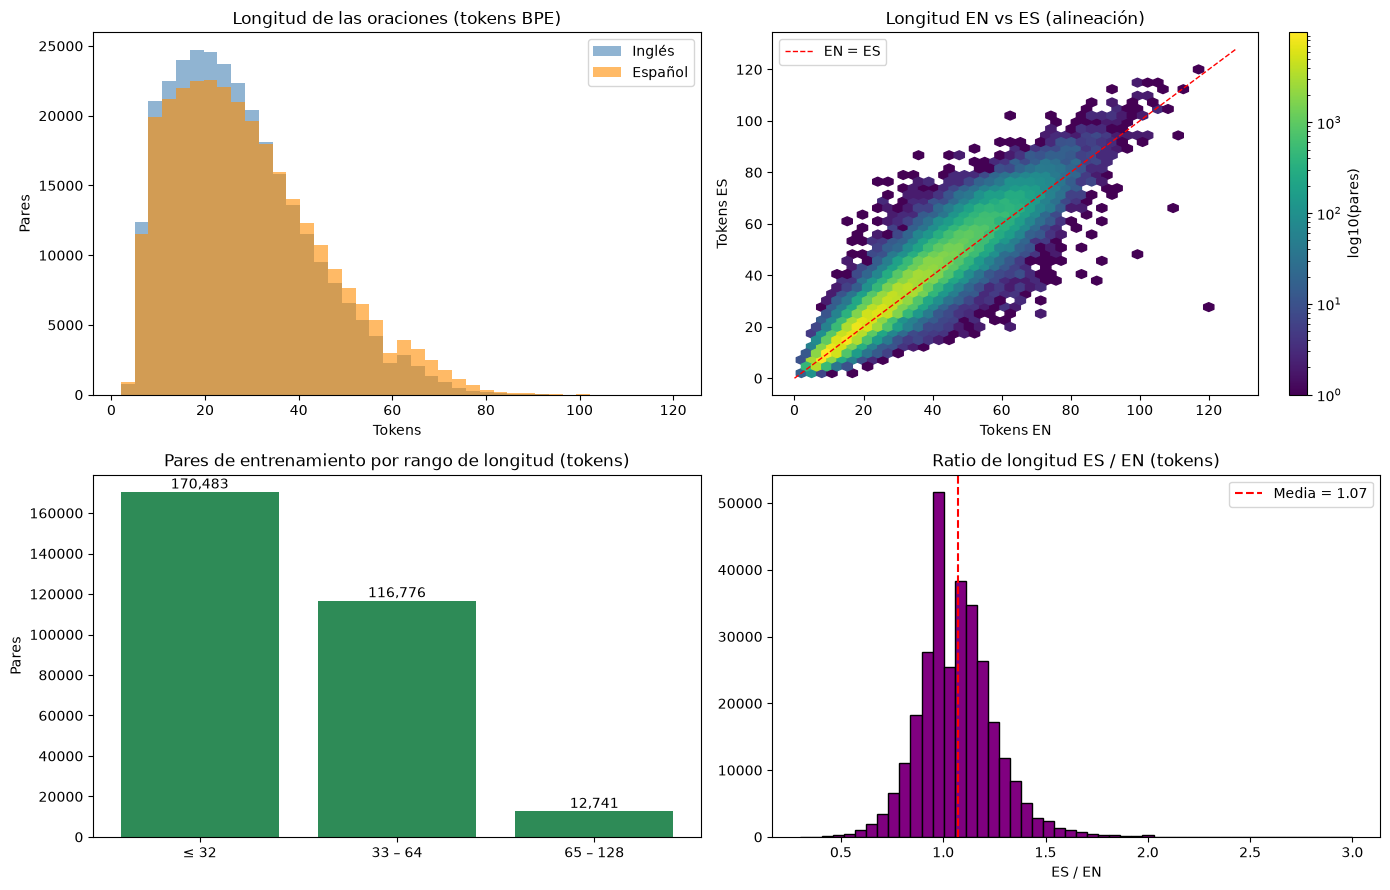

In [6]:
import matplotlib.pyplot as plt

tr = prepared['train']
src_len = np.asarray(tr['src_len']) - 2   # sin BOS/EOS
tgt_len = np.asarray(tr['tgt_len']) - 2

print('=' * 62)
print('RESUMEN DEL CORPUS PREPARADO')
print('=' * 62)
print(f"Pares train / validación / test: {len(prepared['train']):,} / {len(prepared['validation']):,} / {len(prepared['test']):,}")
print(f"Vocabulario BPE: {tok.get_vocab_size():,} tokens")
print(f"Longitud media (tokens)   EN: {src_len.mean():.1f} | ES: {tgt_len.mean():.1f}")
print(f"Longitud máxima (tokens)  EN: {src_len.max()} | ES: {tgt_len.max()}")
print(f"Tokens totales en train   EN: {src_len.sum():,} | ES: {tgt_len.sum():,}")
print(f"Pares con >64 tokens: {int(((src_len > 64) | (tgt_len > 64)).sum()):,}")

if 'en' in tr.column_names:
    n = min(20_000, len(tr))
    idx = sorted(np.random.default_rng(SEED).choice(len(tr), n, replace=False).tolist())
    muestra = tr.select(idx)
    palabras_en = sum(len(t.split()) for t in muestra['en'])
    palabras_es = sum(len(t.split()) for t in muestra['es'])
    tokens_en = sum(muestra['src_len']) - 2 * n
    tokens_es = sum(muestra['tgt_len']) - 2 * n
    print(f"Fertilidad BPE (tokens por palabra, {n:,} pares)  EN: {tokens_en/palabras_en:.2f} | ES: {tokens_es/palabras_es:.2f}")
    print('\nEjemplos de tokenización (la "Ġ" marca el inicio de una palabra):')
    for i in range(3):
        fila = tr[int(idx[i])]
        print(f"  EN: {fila['en']}")
        print(f"  Tokens EN ({len(tok.encode(fila['en']).tokens)}): {tok.encode(fila['en']).tokens[:12]} ...")
        print(f"  ES: {fila['es']}\n")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].hist(src_len, bins=40, alpha=0.6, label='Inglés', color='steelblue')
axes[0, 0].hist(tgt_len, bins=40, alpha=0.6, label='Español', color='darkorange')
axes[0, 0].set_title('Longitud de las oraciones (tokens BPE)')
axes[0, 0].set_xlabel('Tokens'); axes[0, 0].set_ylabel('Pares'); axes[0, 0].legend()

hb = axes[0, 1].hexbin(src_len, tgt_len, gridsize=40, cmap='viridis', mincnt=1, bins='log')
axes[0, 1].plot([0, 128], [0, 128], 'r--', linewidth=1, label='EN = ES')
axes[0, 1].set_title('Longitud EN vs ES (alineación)')
axes[0, 1].set_xlabel('Tokens EN'); axes[0, 1].set_ylabel('Tokens ES'); axes[0, 1].legend()
fig.colorbar(hb, ax=axes[0, 1], label='log10(pares)')

bins = report['train_length_bins']
axes[1, 0].bar(['≤ 32', '33 – 64', '65 – 128'],
               [bins['hasta_32'], bins['33_a_64'], bins['65_a_128']], color='seagreen')
for x, v in enumerate([bins['hasta_32'], bins['33_a_64'], bins['65_a_128']]):
    axes[1, 0].text(x, v, f'{v:,}', ha='center', va='bottom')
axes[1, 0].set_title('Pares de entrenamiento por rango de longitud (tokens)')
axes[1, 0].set_ylabel('Pares')

ratio = tgt_len / np.maximum(src_len, 1)
axes[1, 1].hist(np.clip(ratio, 0.3, 3), bins=50, color='purple', edgecolor='black')
axes[1, 1].axvline(ratio.mean(), color='red', linestyle='--', label=f'Media = {ratio.mean():.2f}')
axes[1, 1].set_title('Ratio de longitud ES / EN (tokens)')
axes[1, 1].set_xlabel('ES / EN'); axes[1, 1].legend()

fig.tight_layout()
fig.savefig(RUN / 'eda_tokens.png', dpi=150)
plt.show()

**4. Batches y Transformer:** el padding completa cada lote hasta su frase más larga. Se agrupan longitudes similares para no desperdiciar memoria. La máscara causal impide que el decoder vea palabras futuras.
Todas las matrices empiezan aleatorias (no se carga un modelo entrenado).

In [7]:
class LengthBatchSampler(Sampler):
    def __init__(self, lengths, batch_size, epoch=0, start_batch=0):
        self.lengths=np.asarray(lengths); self.batch_size=batch_size
        self.epoch=epoch; self.start_batch=start_batch
    def __iter__(self):
        rng=np.random.default_rng(SEED+self.epoch)
        idx=rng.permutation(len(self.lengths)); batches=[]
        pool=self.batch_size*100
        for i in range(0,len(idx),pool):
            part=idx[i:i+pool]; part=part[np.argsort(self.lengths[part],kind='stable')]
            batches.extend(part[j:j+self.batch_size].tolist() for j in range(0,len(part),self.batch_size))
        rng.shuffle(batches)
        yield from batches[self.start_batch:]
    def __len__(self): return math.ceil(len(self.lengths)/self.batch_size)-self.start_batch

def collate(rows):
    def pad(name):
        return nn.utils.rnn.pad_sequence([torch.tensor(r[name],dtype=torch.long) for r in rows],
                                        batch_first=True,padding_value=PAD)
    return pad('src'),pad('tgt')

class Translator(nn.Module):
    def __init__(self,vocab_size,d_model=384,nhead=6,layers=4,d_ff=1536,dropout=0.1,max_positions=512):
        super().__init__(); self.d_model=d_model
        self.embedding=nn.Embedding(vocab_size,d_model,padding_idx=PAD)
        self.dropout=nn.Dropout(dropout)
        pos=torch.arange(max_positions).unsqueeze(1)
        freq=torch.exp(torch.arange(0,d_model,2)*(-math.log(10000.0)/d_model))
        pe=torch.zeros(max_positions,d_model)
        pe[:,0::2]=torch.sin(pos*freq); pe[:,1::2]=torch.cos(pos*freq)
        self.register_buffer('pe',pe.unsqueeze(0))
        self.transformer=nn.Transformer(d_model=d_model,nhead=nhead,num_encoder_layers=layers,
            num_decoder_layers=layers,dim_feedforward=d_ff,dropout=dropout,
            batch_first=True,norm_first=True)
        self.output=nn.Linear(d_model,vocab_size,bias=False)
        self.output.weight=self.embedding.weight
        for p in self.parameters():
            if p.dim()>1: nn.init.xavier_uniform_(p)
        with torch.no_grad(): self.embedding.weight[PAD].zero_()
    def embed(self,x):
        if x.size(1)>self.pe.size(1): raise ValueError('Secuencia excede posiciones disponibles')
        return self.dropout(self.embedding(x)*math.sqrt(self.d_model)+self.pe[:,:x.size(1)])
    def encode(self,src):
        pad=src.eq(PAD)
        return self.transformer.encoder(self.embed(src),src_key_padding_mask=pad),pad
    def decode(self,tgt,memory,src_pad):
        causal=torch.ones(tgt.size(1),tgt.size(1),device=tgt.device,dtype=torch.bool).triu(1)
        hidden=self.transformer.decoder(self.embed(tgt),memory,tgt_mask=causal,
            tgt_key_padding_mask=tgt.eq(PAD),memory_key_padding_mask=src_pad)
        return self.output(hidden)
    def forward(self,src,tgt):
        memory,pad=self.encode(src)
        return self.decode(tgt,memory,pad)

model=Translator(tok.get_vocab_size(),**MODEL_ARGS).to(device)
print('Parámetros:',f'{sum(p.numel() for p in model.parameters()):,}')
train_lengths=np.maximum(np.asarray(prepared['train']['src_len']),np.asarray(prepared['train']['tgt_len']))

d:\topicosML\.venv\Lib\site-packages\torch\nn\modules\transformer.py:143: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = TransformerEncoder(


Parámetros: 22,709,760


**5. Pruebas previas:** se verifica que el padding y el futuro no alteren posiciones anteriores, que la pérdida sea finita y que un modelo pequeño pueda memorizar unos pocos pares. Esto prueba el funcionamiento del código, no la calidad del traductor.

In [8]:
def technical_checks():
    cuda_devices=[torch.cuda.current_device()] if device.type=='cuda' else []
    with torch.random.fork_rng(devices=cuda_devices):
        tiny=Translator(tok.get_vocab_size(),d_model=32,nhead=4,layers=1,d_ff=64,dropout=0).to(device)
        rows=[prepared['train'][i] for i in range(4)]
        src,tgt=(x.to(device) for x in collate(rows))
        src=src[:,:min(24,src.size(1))]; tgt=tgt[:,:min(24,tgt.size(1))]
        tiny.eval()
        with torch.no_grad():
            a=tiny(src,tgt[:,:-1])
            b=tiny(F.pad(src,(0,3),value=PAD),tgt[:,:-1])
            torch.testing.assert_close(a,b,atol=1e-4,rtol=1e-4)
        opt=torch.optim.Adam(tiny.parameters(),lr=0.01)
        losses=[]
        for _ in range(60):
            opt.zero_grad()
            out=tiny(src,tgt[:,:-1])
            loss=F.cross_entropy(out.reshape(-1,out.size(-1)),tgt[:,1:].reshape(-1),ignore_index=PAD)
            loss.backward(); opt.step(); losses.append(loss.item())
        print('Pruebas OK. Pérdida de memorización:',round(losses[0],3),'→',round(losses[-1],3))
technical_checks()

Pruebas OK. Pérdida de memorización: 9.682 → 0.336


**6. Entrenamiento con reanudación:** la pérdida se calcula con el español desplazado:

Entrada `BOS Tengo hambre`, objetivo `Tengo hambre EOS`.

*   Se acumulan gradientes (batch efectivo de 256 frases) y se normalizan por el número real de tokens. Se usa precisión mixta en GPU y clipping del gradiente.
*   El learning rate sigue el schedule de Noam con warmup; su valor pico depende de `WARMUP`.
*   Se entrena con *label smoothing* = 0.1, pero lo que se **reporta** por época es la pérdida real (NLL por token, sin smoothing) y su perplejidad `exp(pérdida)`, tanto en train como en validación.
*   Al final de cada época se traducen tres frases fijas (greedy) para ver cómo evoluciona la calidad. Se guarda el mejor checkpoint (`best.pt`) según la pérdida de validación y el historial en `history.json`.

In [9]:
optimizer=torch.optim.AdamW(model.parameters(),lr=0.0,betas=(0.9,0.98),eps=1e-9,weight_decay=0.01)
amp_enabled=device.type=='cuda'
amp_dtype=torch.bfloat16 if amp_enabled and torch.cuda.is_bf16_supported() else torch.float16
scaler=torch.amp.GradScaler('cuda',enabled=amp_enabled and amp_dtype==torch.float16)

def autocast(): return torch.autocast(device_type=device.type,dtype=amp_dtype,enabled=amp_enabled)
def lr_at(step): return MODEL_ARGS['d_model']**-0.5 * min(step**-0.5,step*WARMUP**-1.5)
def fmt_time(sec):
    m,s=divmod(int(sec),60); return f'{m}m {s:02d}s'
def atomic_save(obj,path):
    tmp=path.with_suffix('.tmp'); torch.save(obj,tmp); os.replace(tmp,path)
def rng_state():
    return dict(py=random.getstate(),np=np.random.get_state(),torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if device.type=='cuda' else None)
def restore_rng(r):
    random.setstate(r['py']); np.random.set_state(r['np']); torch.set_rng_state(r['torch'])
    if r['cuda'] is not None and device.type=='cuda': torch.cuda.set_rng_state_all(r['cuda'])

state=dict(epoch=0,next_batch=0,step=0,best=float('inf'),history=[],epoch_loss=0.0,
           epoch_nll=0.0,epoch_tokens=0,epoch_seconds=0.0)
identity=dict(spec=spec,tokenizer=report['tokenizer_sha256'],data=report['train_fingerprint'])

if (RUN/'last.pt').exists():
    ck=torch.load(RUN/'last.pt',map_location='cpu',weights_only=False)
    model.load_state_dict(ck['model']); optimizer.load_state_dict(ck['optimizer'])
    for s in optimizer.state.values():
        for k,v in s.items():
            if torch.is_tensor(v) and k!='step': s[k]=v.to(device)
    scaler.load_state_dict(ck['scaler']); state=ck['state']; restore_rng(ck['rng'])
    state.setdefault('epoch_nll',0.0)
    print('Reanudado:',state['epoch'],'épocas completas; paso',state['step'])

def save_last():
    atomic_save(dict(model=model.state_dict(),optimizer=optimizer.state_dict(),scaler=scaler.state_dict(),
        state=state,identity=identity,rng=rng_state()),RUN/'last.pt')

val_short=prepared['validation'].filter(lambda r:max(r['src_len'],r['tgt_len'])<=MAX_TOKENS)
val_loader=DataLoader(val_short,batch_size=BATCH_SIZE,collate_fn=collate,num_workers=0)

@torch.inference_mode()
def validation_loss():
    """Pérdida real por token (NLL, sin label smoothing) -> perplejidad = exp(pérdida)."""
    model.eval(); total=0.0; tokens=0
    for src,tgt in tqdm(val_loader,desc='Evaluando',leave=True):
        src,tgt=src.to(device),tgt.to(device)
        with autocast():
            logits=model(src,tgt[:,:-1])
            loss=F.cross_entropy(logits.reshape(-1,logits.size(-1)),tgt[:,1:].reshape(-1),
                                 ignore_index=PAD,reduction='sum')
        total+=loss.item(); tokens+=tgt[:,1:].ne(PAD).sum().item()
    return total/tokens

# Frases fijas para ver cómo "aprende a traducir" el modelo época tras época
SAMPLE_SENTENCES=['I am hungry.',
                  'The government announced new measures to reduce inflation.',
                  'Although it was raining heavily, we decided to walk to the station.']

@torch.inference_mode()
def greedy_sample(text,max_new=60):
    model.eval()
    src=torch.tensor([[BOS]+tok.encode(clean_text(text)).ids+[EOS]],device=device)
    with autocast():
        memory,pad=model.encode(src)
        ids=[BOS]
        for _ in range(max_new):
            out=model.decode(torch.tensor([ids],device=device),memory,pad)[0,-1].float()
            out[[PAD,BOS,UNK]]=-float('inf')
            nxt=int(out.argmax()); ids.append(nxt)
            if nxt==EOS: break
    return tok.decode(ids,skip_special_tokens=True)

# Resumen de configuración (útil para el informe)
n_train=len(prepared['train'])
steps_per_epoch=math.ceil(math.ceil(n_train/BATCH_SIZE)/ACCUM_STEPS)
print('='*62)
print('CONFIGURACIÓN DEL ENTRENAMIENTO')
print('='*62)
print(f"Modo: {MODO} | Pares train: {n_train:,} | Parámetros: {sum(p.numel() for p in model.parameters()):,}")
print(f"Batch: {BATCH_SIZE} x {ACCUM_STEPS} acumulación = {BATCH_SIZE*ACCUM_STEPS} frases por paso")
print(f"Pasos por época: {steps_per_epoch:,} | Épocas: {EPOCHS} | Pasos totales: {steps_per_epoch*EPOCHS:,}")
print(f"Warmup: {WARMUP} pasos | LR pico: {lr_at(WARMUP):.2e} | Label smoothing: 0.1 | Dispositivo: {device.type} ({amp_dtype if amp_enabled else 'fp32'})")
print('='*62)

if EJECUTAR_ENTRENAMIENTO:
    print('Iniciando entrenamiento...')
    for epoch in range(state['epoch'],EPOCHS):
        first_batch=state['next_batch']
        sampler=LengthBatchSampler(train_lengths,BATCH_SIZE,epoch,first_batch)
        loader=DataLoader(prepared['train'],batch_sampler=sampler,collate_fn=collate,num_workers=0,
                          pin_memory=True,generator=torch.Generator().manual_seed(SEED+epoch))
        model.train(); optimizer.zero_grad(set_to_none=True)
        window_tokens=0; window_batches=0; start=time.monotonic()
        previous_seconds=state['epoch_seconds']
        pbar=tqdm(loader,desc='Entrenando',leave=True)

        for offset,(src,tgt) in enumerate(pbar):
            absolute_batch=first_batch+offset
            src,tgt=src.to(device),tgt.to(device)
            target=tgt[:,1:].reshape(-1)
            with autocast():
                logits=model(src,tgt[:,:-1])
                flat=logits.reshape(-1,logits.size(-1))
                loss=F.cross_entropy(flat,target,ignore_index=PAD,label_smoothing=0.1,reduction='sum')
                with torch.no_grad():  # pérdida real (sin smoothing) solo para reportar
                    nll=F.cross_entropy(flat.detach(),target,ignore_index=PAD,reduction='sum')
            scaler.scale(loss/4096.0).backward()
            nt=tgt[:,1:].ne(PAD).sum().item()
            window_tokens+=nt; window_batches+=1
            state['epoch_loss']+=loss.item(); state['epoch_nll']+=nll.item(); state['epoch_tokens']+=nt

            if window_batches==ACCUM_STEPS or offset+1==len(loader):
                scaler.unscale_(optimizer)
                for p in model.parameters():
                    if p.grad is not None: p.grad.mul_(4096.0/window_tokens)
                nn.utils.clip_grad_norm_(model.parameters(),1.0)
                for group in optimizer.param_groups: group['lr']=lr_at(state['step']+1)
                old_scale=scaler.get_scale(); scaler.step(optimizer); scaler.update()
                if scaler.get_scale()>=old_scale: state['step']+=1
                optimizer.zero_grad(set_to_none=True); window_tokens=0; window_batches=0
                state['epoch']=epoch; state['next_batch']=absolute_batch+1
                state['epoch_seconds']=previous_seconds+time.monotonic()-start
                pbar.set_postfix(loss=round(state['epoch_nll']/state['epoch_tokens'],3),step=state['step'])
                if state['step']>0 and state['step']%SAVE_EVERY==0: save_last()

        tl=state['epoch_nll']/state['epoch_tokens']
        vl=validation_loss()
        samples=[[s,greedy_sample(s)] for s in SAMPLE_SENTENCES]
        row=dict(epoch=epoch+1,step=state['step'],train_loss=tl,val_loss=vl,
                 train_ppl=math.exp(tl),val_ppl=math.exp(vl),minutes=state['epoch_seconds']/60,
                 samples=samples)
        state['history'].append(row)
        print(f"Época: {epoch+1:02d} | Tiempo: {fmt_time(state['epoch_seconds'])}")
        print(f"        Pérdida Train: {tl:.3f} | Perplejidad Train: {math.exp(tl):8.3f}")
        print(f"        Pérdida Val:   {vl:.3f} | Perplejidad Val:   {math.exp(vl):8.3f}")
        print('        Traducciones de muestra (greedy):')
        for en_s,es_s in samples: print(f'          EN: {en_s}\n          ES: {es_s}')
        if vl<state['best']:
            state['best']=vl
            atomic_save(dict(model=model.state_dict(),identity=identity,epoch=epoch+1,val_loss=vl),RUN/'best.pt')
        state.update(epoch=epoch+1,next_batch=0,epoch_loss=0.0,epoch_nll=0.0,epoch_tokens=0,epoch_seconds=0.0)
        save_last()
        (RUN/'history.json').write_text(json.dumps(state['history'],indent=2,ensure_ascii=False),encoding='utf-8')
else:
    print('Preparación lista. Cambia EJECUTAR_ENTRENAMIENTO=True para iniciar.')

Filter: 100%|██████████| 2000/2000 [00:00<00:00, 292836.98 examples/s]


CONFIGURACIÓN DEL ENTRENAMIENTO
Modo: piloto | Pares train: 300,000 | Parámetros: 22,709,760
Batch: 64 x 4 acumulación = 256 frases por paso
Pasos por época: 1,172 | Épocas: 8 | Pasos totales: 9,376
Warmup: 1500 pasos | LR pico: 1.32e-03 | Label smoothing: 0.1 | Dispositivo: cuda (torch.bfloat16)
Iniciando entrenamiento...


Evaluando: 100%|██████████| 32/32 [00:00<00:00, 42.55it/s]


Época: 01 | Tiempo: 3m 07s
        Pérdida Train: 5.089 | Perplejidad Train:  162.154
        Pérdida Val:   2.802 | Perplejidad Val:     16.472
        Traducciones de muestra (greedy):
          EN: I am hungry.
          ES: Me diura.
          EN: The government announced new measures to reduce inflation.
          ES: El gobierno anunció nuevas medidas para reducir la inflación.
          EN: Although it was raining heavily, we decided to walk to the station.
          ES: Aunque se ha dado lugar a la luz, decidimos a la temperatura.


Evaluando: 100%|██████████| 32/32 [00:00<00:00, 43.15it/s]


Época: 02 | Tiempo: 3m 07s
        Pérdida Train: 2.465 | Perplejidad Train:   11.763
        Pérdida Val:   1.929 | Perplejidad Val:      6.880
        Traducciones de muestra (greedy):
          EN: I am hungry.
          ES: Mejoré.
          EN: The government announced new measures to reduce inflation.
          ES: El gobierno anunció nuevas medidas para reducir la inflación.
          EN: Although it was raining heavily, we decided to walk to the station.
          ES: Aunque estaba muy bien, decidimos caminar hacia la estación.


... (8 outputs left out)

Evaluando: 100%|██████████| 32/32 [00:00<00:00, 43.05it/s]


Época: 07 | Tiempo: 3m 06s
        Pérdida Train: 1.517 | Perplejidad Train:    4.557
        Pérdida Val:   1.451 | Perplejidad Val:      4.269
        Traducciones de muestra (greedy):
          EN: I am hungry.
          ES: Me estoy hambriento.
          EN: The government announced new measures to reduce inflation.
          ES: El Gobierno anunció nuevas medidas para reducir la inflación.
          EN: Although it was raining heavily, we decided to walk to the station.
          ES: Aunque estaba lloviendo en gran medida, decidimos caminar a la estación.


Evaluando: 100%|██████████| 32/32 [00:00<00:00, 42.84it/s]


Época: 08 | Tiempo: 3m 08s
        Pérdida Train: 1.469 | Perplejidad Train:    4.346
        Pérdida Val:   1.428 | Perplejidad Val:      4.170
        Traducciones de muestra (greedy):
          EN: I am hungry.
          ES: Estoy hambriento.
          EN: The government announced new measures to reduce inflation.
          ES: El gobierno anunció nuevas medidas para reducir la inflación.
          EN: Although it was raining heavily, we decided to walk to the station.
          ES: Aunque estaba lloviendo fuertemente, decidimos caminar a la estación.


**6.1 Curvas y métricas del entrenamiento:** tabla con el historial por época (también en CSV), curva de pérdida train vs validación, perplejidad, schedule del learning rate y brecha de generalización (val − train). Se guardan como `curva_perdida.png` y `metricas_entrenamiento.png`. También imprime las traducciones de muestra de cada época.

 epoch  step  train_loss  val_loss  train_ppl  val_ppl  brecha  minutes
     1  1172       5.089     2.802    162.154   16.472  -2.287    3.129
     2  2344       2.465     1.929     11.763    6.880  -0.536    3.121
     3  3516       1.964     1.703      7.130    5.492  -0.261    3.119
     4  4688       1.769     1.590      5.864    4.904  -0.179    3.115
     5  5860       1.654     1.526      5.230    4.599  -0.129    3.126
     6  7032       1.576     1.481      4.836    4.399  -0.095    3.126
     7  8204       1.517     1.451      4.557    4.269  -0.065    3.104
     8  9376       1.469     1.428      4.346    4.170  -0.041    3.136

Tiempo total: 25.0 min | Mejor época (val): 8 (pérdida 1.428, perplejidad 4.2)


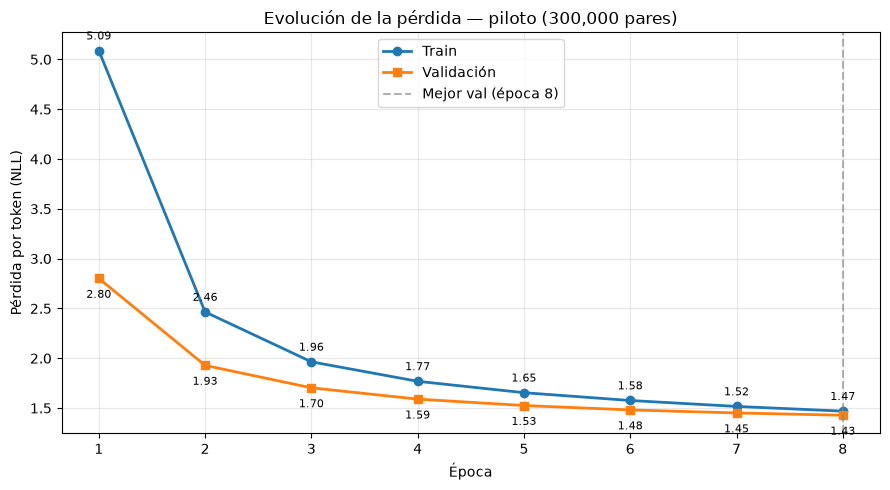

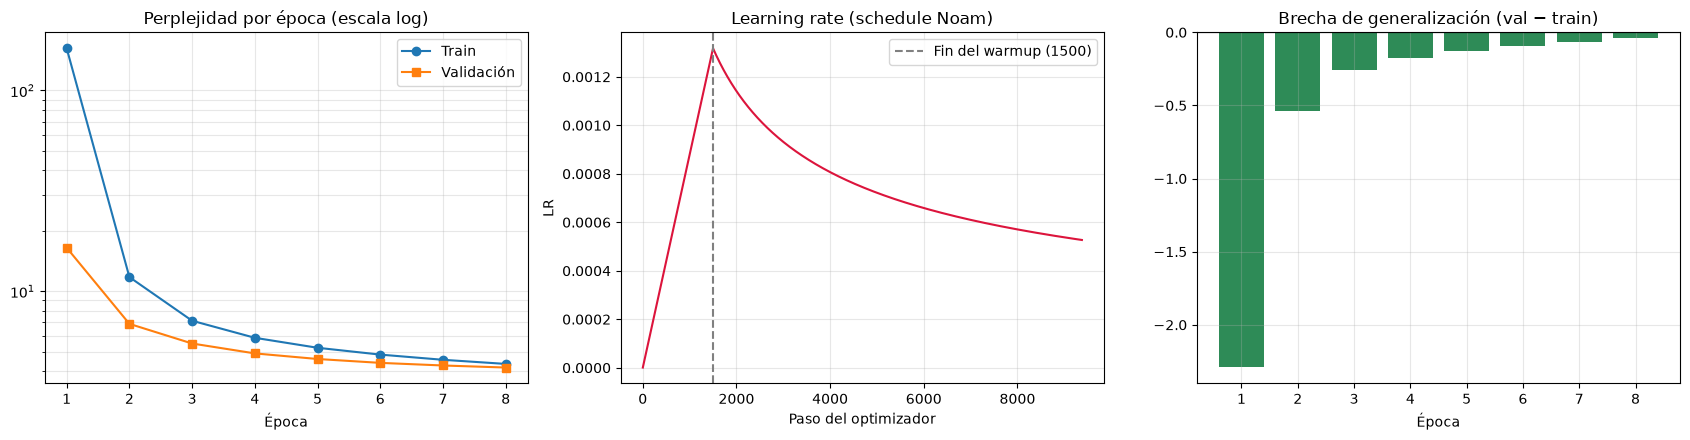


TRADUCCIONES DE MUESTRA POR ÉPOCA (greedy)

--- Época 1 ---
  EN: I am hungry.
  ES: Me diura.
  EN: The government announced new measures to reduce inflation.
  ES: El gobierno anunció nuevas medidas para reducir la inflación.
  EN: Although it was raining heavily, we decided to walk to the station.
  ES: Aunque se ha dado lugar a la luz, decidimos a la temperatura.

--- Época 2 ---
  EN: I am hungry.
  ES: Mejoré.
  EN: The government announced new measures to reduce inflation.
  ES: El gobierno anunció nuevas medidas para reducir la inflación.
  EN: Although it was raining heavily, we decided to walk to the station.
  ES: Aunque estaba muy bien, decidimos caminar hacia la estación.

--- Época 3 ---
  EN: I am hungry.
  ES: Estoy hambruna.
  EN: The government announced new measures to reduce inflation.
  ES: El gobierno anunció nuevas medidas para reducir la inflación.
  EN: Although it was raining heavily, we decided to walk to the station.
  ES: Aunque estaba lentamente, decidimo

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

hist_path = RUN / 'history.json'
history = json.loads(hist_path.read_text(encoding='utf-8')) if hist_path.exists() else state['history']

if not history:
    print('Todavía no hay historial: entrena al menos una época.')
else:
    df = pd.DataFrame(history)
    df['train_ppl'] = np.exp(df['train_loss'])
    df['val_ppl'] = np.exp(df['val_loss'])
    df['brecha'] = df['val_loss'] - df['train_loss']
    mejor = int(df.loc[df['val_loss'].idxmin(), 'epoch'])

    cols = ['epoch', 'step', 'train_loss', 'val_loss', 'train_ppl', 'val_ppl', 'brecha', 'minutes']
    print(df[cols].round(3).to_string(index=False))
    df[cols].round(4).to_csv(RUN / 'historial_entrenamiento.csv', index=False)
    print(f"\nTiempo total: {df['minutes'].sum():.1f} min | Mejor época (val): {mejor} "
          f"(pérdida {df['val_loss'].min():.3f}, perplejidad {df['val_ppl'].min():.1f})")

    ep = df['epoch'].tolist(); tr = df['train_loss'].tolist(); va = df['val_loss'].tolist()

    # Figura 1: evolución de la pérdida
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(ep, tr, marker='o', linewidth=2, label='Train')
    ax.plot(ep, va, marker='s', linewidth=2, label='Validación')
    ax.axvline(mejor, linestyle='--', color='gray', alpha=0.6, label=f'Mejor val (época {mejor})')
    for x, y in zip(ep, tr):
        ax.annotate(f'{y:.2f}', (x, y), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
    for x, y in zip(ep, va):
        ax.annotate(f'{y:.2f}', (x, y), textcoords='offset points', xytext=(0, -14), ha='center', fontsize=8)
    ax.set_xlabel('Época'); ax.set_ylabel('Pérdida por token (NLL)')
    ax.set_title(f'Evolución de la pérdida — {MODO} ({TARGET_PAIRS:,} pares)')
    ax.set_xticks(ep); ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout(); fig.savefig(RUN / 'curva_perdida.png', dpi=150); plt.show()

    # Figura 2: perplejidad, learning rate y brecha train-val
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    axes[0].plot(ep, df['train_ppl'], marker='o', label='Train')
    axes[0].plot(ep, df['val_ppl'], marker='s', label='Validación')
    axes[0].set_yscale('log'); axes[0].set_title('Perplejidad por época (escala log)')
    axes[0].set_xlabel('Época'); axes[0].set_xticks(ep); axes[0].grid(alpha=0.3, which='both'); axes[0].legend()

    ultimo_paso = int(df['step'].max())
    pasos = np.arange(1, ultimo_paso + 1)
    axes[1].plot(pasos, [lr_at(int(s)) for s in pasos], color='crimson')
    axes[1].axvline(WARMUP, linestyle='--', color='gray', label=f'Fin del warmup ({WARMUP})')
    axes[1].set_title('Learning rate (schedule Noam)')
    axes[1].set_xlabel('Paso del optimizador'); axes[1].set_ylabel('LR'); axes[1].grid(alpha=0.3); axes[1].legend()

    axes[2].bar(ep, df['brecha'], color=['seagreen' if b <= 0.15 else 'indianred' for b in df['brecha']])
    axes[2].axhline(0, color='black', linewidth=0.8)
    axes[2].set_title('Brecha de generalización (val − train)')
    axes[2].set_xlabel('Época'); axes[2].set_xticks(ep); axes[2].grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(RUN / 'metricas_entrenamiento.png', dpi=150); plt.show()

    # Evolución cualitativa: la misma frase traducida al final de cada época
    if 'samples' in df.columns:
        print('\nTRADUCCIONES DE MUESTRA POR ÉPOCA (greedy)')
        for _, fila in df.iterrows():
            if isinstance(fila['samples'], list):
                print(f"\n--- Época {int(fila['epoch'])} ---")
                for en, es in fila['samples']:
                    print(f"  EN: {en}\n  ES: {es}")

**7. Traducir con beam search:** el beam search mantiene varias posibles traducciones. Se normaliza la suma de log-probabilidades por `((5+longitud)/6)**alpha`. Se detiene antes de tiempo cuando ya hay `beam` traducciones terminadas y ninguna de las que siguen en curso las supera. Es una búsqueda aproximada, sin caché de claves o valores.

In [11]:
@torch.inference_mode()
def beam_ids(src_ids,beam=3,alpha=0.6,max_new_tokens=127):
    model.eval()
    src=torch.tensor([src_ids],device=device)
    memory,src_pad=model.encode(src)
    if beam==1:
        ids=[BOS]
        for _ in range(max_new_tokens):
            out=model.decode(torch.tensor([ids],device=device),memory,src_pad)[0,-1].float()
            out[[PAD,BOS,UNK]]=-float('inf')
            ids.append(int(out.argmax()))
            if ids[-1]==EOS: return ids,False
        return ids,True
    alive=[([BOS],0.0)]; finished=[]
    def score(item):
        ids,logp=item
        return logp/(((5+max(1,len(ids)-1))/6)**alpha)
    for _ in range(max_new_tokens):
        tgt=torch.tensor([ids for ids,_ in alive],device=device)
        out=model.decode(tgt,memory.expand(len(alive),-1,-1),src_pad.expand(len(alive),-1))
        logp=F.log_softmax(out[:,-1].float(),dim=-1)
        logp[:,[PAD,BOS,UNK]]=-float('inf')
        values,indices=logp.topk(min(beam*2,logp.size(-1)),dim=-1)
        candidates=[]
        for i,(ids,base) in enumerate(alive):
            for v,j in zip(values[i].tolist(),indices[i].tolist()):
                candidate=(ids+[j],base+v)
                (finished if j==EOS else candidates).append(candidate)
        finished=sorted(finished,key=score,reverse=True)[:beam]
        alive=sorted(candidates,key=score,reverse=True)[:beam]
        if not alive: break
        # Parada anticipada: ya hay `beam` traducciones terminadas y ninguna en curso las supera
        if len(finished)==beam and score(alive[0])<score(finished[-1]): break
    best=max(finished+alive,key=score)
    return best[0],best[0][-1]!=EOS

def split_source(text):
    text=clean_text(text)
    if not text: return []
    limit=MAX_TOKENS-2; chunks=[]
    for sentence in re.split(r'(?<=[.!?])\s+',text):
        current=''
        for word in sentence.split():
            proposal=(current+' '+word).strip()
            if len(tok.encode(proposal).ids)<=limit:
                current=proposal
            else:
                if current: chunks.append(current)
                current=word
        if current: chunks.append(current)
    return chunks

def translate(text,beam=3,alpha=0.6):
    if len(tok.encode(clean_text(text)).ids)<=MAX_TOKENS-2:
        chunks=[clean_text(text)] if clean_text(text) else []
    else: chunks=split_source(text)
    outputs=[]; capped=0
    for chunk in chunks:
        ids,hit_cap=beam_ids([BOS]+tok.encode(chunk).ids+[EOS],beam=beam,alpha=alpha,max_new_tokens=MAX_TOKENS-1)
        outputs.append(tok.decode(ids,skip_special_tokens=True)); capped+=int(hit_cap)
    return ' '.join(outputs),dict(chunks=len(chunks),capped=capped)

BEST_LOADED=False
if (RUN/'best.pt').exists():
    best=torch.load(RUN/'best.pt',map_location='cpu',weights_only=False)
    model.load_state_dict(best['model']); model.eval(); BEST_LOADED=True
    print('Mejor checkpoint cargado.')

Mejor checkpoint cargado.


**8. Evaluación final con BLEU y chrF++:** se evalúa el texto reconstruido sobre el test set con métricas estadísticas, que no usan modelos preentrenados:

*   **SacreBLEU:** evalúa la similitud superficial y la exactitud léxica.
*   **chrF++:** complementa a BLEU con coincidencias a nivel de caracteres y bigramas de palabras (útil para español).
*   **COMET (opcional, `USE_COMET`):** estima la calidad semántica con un modelo multilingüe preentrenado. Se usa **solo como métrica de evaluación**: no interviene en el entrenamiento ni en la generación del traductor. Está desactivado por defecto. Actívalo únicamente al evaluar el checkpoint final, porque consume bastante VRAM (si hay error OOM, déjalo en `False`) y requiere instalar `unbabel-comet` por separado.

Para generar las traducciones del test, pon `EJECUTAR_TEST_FINAL = True` en la celda de configuración antes de ejecutar la celda de evaluación.

In [16]:
USE_COMET = False  # Activa solo al evaluar el checkpoint final; requiere instalar unbabel-comet por separado

if USE_COMET:
    from comet import download_model, load_from_checkpoint
    print("Cargando modelo COMET...")
    comet_model_path = download_model("Unbabel/wmt22-comet-da")
    comet_model = load_from_checkpoint(comet_model_path)
    comet_model.eval()

def score_predictions(sources, predictions, references):
    bleu = BLEU(tokenize='13a'); chrf = CHRF(word_order=2)
    b = bleu.corpus_score(predictions, [references])
    c = chrf.corpus_score(predictions, [references])

    result = dict(bleu=b.score, chrf_plus_plus=c.score, n=len(predictions),
                  brevity_penalty=b.bp, length_ratio=b.sys_len/max(1, b.ref_len))

    if USE_COMET and sources is not None:
        data = [{"src": src, "mt": mt, "ref": ref} for src, mt, ref in zip(sources, predictions, references)]
        comet_output = comet_model.predict(data, batch_size=8, gpus=1 if device.type == 'cuda' else 0)
        result['comet_score'] = comet_output.system_score

    return result

def evaluate_generation(ds, name, beam=3, alpha=0.6):
    assert BEST_LOADED, 'Entrena y carga el mejor checkpoint primero.'
    rows = []
    for r in tqdm(ds, desc=name):
        hyp, meta = translate(r['en'], beam=beam, alpha=alpha)
        rows.append(dict(en=r['en'], reference=r['es'], hypothesis=hyp, **meta))

    sources = [r['en'] for r in rows]
    predictions = [r['hypothesis'] for r in rows]
    references = [r['reference'] for r in rows]

    result = score_predictions(sources, predictions, references)
    result.update(beam=beam, alpha=alpha)

    with (RUN/(name+'_translations.jsonl')).open('w', encoding='utf-8') as f:
        for r in rows: f.write(json.dumps(r, ensure_ascii=False)+'\n')

    (RUN/(name+'_metrics.json')).write_text(json.dumps(result, indent=2), encoding='utf-8')
    print(json.dumps(result, indent=2))
    return result

# Se evalúa en el TEST set final (Asegúrate que el modelo esté entrenado y haya generado el best.pt)
if EJECUTAR_TEST_FINAL:
    evaluate_generation(prepared['test'], 'test_final', beam=3, alpha=0.6)


**8.1 Análisis del test y ejemplos para el reporte:** a partir de `test_final_translations.jsonl` calcula chrF++ por oración y BLEU según la longitud de la frase, y detecta posibles problemas (copia del origen, repeticiones, traducción truncada, muy corta o muy larga, números distintos). Genera `analisis_test.png` y exporta `ejemplos_test_100.xlsx` con 50 traducciones buenas y 50 fallidas.

In [13]:
import pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from sacrebleu.metrics import BLEU, CHRF

ruta = RUN / 'test_final_translations.jsonl'
if not ruta.exists():
    print('Primero ejecuta la evaluación final (EJECUTAR_TEST_FINAL=True) para generar test_final_translations.jsonl')
else:
    df = pd.read_json(ruta, lines=True)
    metricas_path = RUN / 'test_final_metrics.json'
    if metricas_path.exists():
        m = json.loads(metricas_path.read_text(encoding='utf-8'))
        print(f"MÉTRICAS GLOBALES (test, n={m['n']}): BLEU = {m['bleu']:.2f} | chrF++ = {m['chrf_plus_plus']:.2f} | "
              f"brevity penalty = {m['brevity_penalty']:.3f} | ratio de longitud = {m['length_ratio']:.3f}")

    chrf = CHRF(word_order=2)
    df['chrf'] = [chrf.sentence_score(h, [r]).score for h, r in zip(df['hypothesis'], df['reference'])]
    df['palabras_en'] = df['en'].str.split().str.len()
    df['ratio_len'] = df['hypothesis'].str.split().str.len() / df['reference'].str.split().str.len().clip(lower=1)

    def tiene_repeticion(texto, n=3, veces=3):
        w = texto.lower().split()
        if len(w) < n * veces: return False
        return max(Counter(tuple(w[i:i + n]) for i in range(len(w) - n + 1)).values()) >= veces

    def numeros(texto): return sorted(re.findall(r'\d+', texto))

    def detectar(fila):
        f = []
        if fila['hypothesis'].strip().lower() == fila['en'].strip().lower(): f.append('copia_del_origen')
        if tiene_repeticion(fila['hypothesis']): f.append('repeticion')
        if fila.get('capped', 0) > 0: f.append('truncada_por_limite')
        if fila['ratio_len'] < 0.6: f.append('muy_corta')
        if fila['ratio_len'] > 1.6: f.append('muy_larga')
        if numeros(fila['en']) != numeros(fila['hypothesis']): f.append('numeros_distintos')
        return f
    df['flags'] = df.apply(detectar, axis=1)

    # BLEU y chrF por rango de longitud de la frase de entrada
    rangos = [(1, 10, '1-10'), (11, 20, '11-20'), (21, 30, '21-30'), (31, 40, '31-40'), (41, 999, '41+')]
    filas = []
    for lo, hi, nombre in rangos:
        sub = df[(df['palabras_en'] >= lo) & (df['palabras_en'] <= hi)]
        if len(sub):
            filas.append(dict(palabras=nombre, n=len(sub),
                              bleu=BLEU(tokenize='13a').corpus_score(sub['hypothesis'].tolist(), [sub['reference'].tolist()]).score,
                              chrf_medio=sub['chrf'].mean()))
    por_largo = pd.DataFrame(filas)
    print('\nRENDIMIENTO POR LONGITUD DE LA FRASE EN INGLÉS')
    print(por_largo.round(2).to_string(index=False))

    conteo = Counter(f for fl in df['flags'] for f in fl)
    print('\nPOSIBLES PROBLEMAS DETECTADOS (una frase puede tener varios)')
    for k, v in conteo.most_common():
        print(f"  {k:<22} {v:>5}  ({100 * v / len(df):.1f}%)")

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    axes[0, 0].bar(por_largo['palabras'], por_largo['bleu'], color='steelblue')
    for x, (b, n) in enumerate(zip(por_largo['bleu'], por_largo['n'])):
        axes[0, 0].text(x, b, f'{b:.1f}\n(n={n})', ha='center', va='bottom', fontsize=8)
    axes[0, 0].set_title('BLEU según longitud de la frase (palabras EN)')
    axes[0, 0].set_xlabel('Palabras'); axes[0, 0].set_ylabel('BLEU')

    axes[0, 1].hist(df['chrf'], bins=30, color='darkorange', edgecolor='black')
    axes[0, 1].axvline(df['chrf'].mean(), color='red', linestyle='--', label=f"Media = {df['chrf'].mean():.1f}")
    axes[0, 1].set_title('Distribución de chrF++ por oración'); axes[0, 1].set_xlabel('chrF++'); axes[0, 1].legend()

    axes[1, 0].hist(df['ratio_len'].clip(0, 3), bins=40, color='purple', edgecolor='black')
    axes[1, 0].axvline(1, color='red', linestyle='--', label='Longitud igual a la referencia')
    axes[1, 0].set_title('Longitud traducción / referencia (palabras)'); axes[1, 0].legend()

    if conteo:
        nombres, valores = zip(*conteo.most_common())
        axes[1, 1].barh(nombres[::-1], [100 * v / len(df) for v in valores][::-1], color='indianred')
    axes[1, 1].set_title('Frases con posibles problemas (% del test)'); axes[1, 1].set_xlabel('%')
    fig.tight_layout(); fig.savefig(RUN / 'analisis_test.png', dpi=150); plt.show()

    # 100 ejemplos para el informe: 50 mejores y 50 peores (frases de >= 4 palabras)
    pool = df[df['palabras_en'] >= 4]
    buenos = pool.sort_values('chrf', ascending=False).head(50).assign(categoria='bueno')
    fallidos = pool.sort_values('chrf', ascending=True).head(50).assign(categoria='fallido')
    ej = pd.concat([buenos, fallidos])[['categoria', 'en', 'reference', 'hypothesis', 'chrf', 'flags']].copy()
    ej['flags'] = ej['flags'].apply(', '.join)
    ej['chrf'] = ej['chrf'].round(1)
    ej.columns = ['categoria', 'ingles', 'referencia', 'traduccion_modelo', 'chrf', 'problemas']
    ej.to_excel(RUN / 'ejemplos_test_100.xlsx', index=False)
    ej.to_csv(RUN / 'ejemplos_test_100.csv', index=False, encoding='utf-8-sig')
    print(f"\nGuardado: {RUN / 'ejemplos_test_100.xlsx'}")

    for titulo, parte in [('MEJORES TRADUCCIONES', buenos.head(5)), ('PEORES TRADUCCIONES', fallidos.head(5))]:
        print(f'\n{titulo}')
        for _, r in parte.iterrows():
            print(f"  EN : {r['en']}\n  REF: {r['reference']}\n  MOD: {r['hypothesis']}  (chrF++ {r['chrf']:.1f})\n")
    try:
        from google.colab import files
        files.download(str(RUN / 'ejemplos_test_100.xlsx'))
    except Exception:
        pass

Primero ejecuta la evaluación final (EJECUTAR_TEST_FINAL=True) para generar test_final_translations.jsonl


**9. Pruebas Interactivas de Traducción:** celdas para probar el rendimiento del modelo con diferentes longitudes de texto.

In [17]:
if BEST_LOADED:
    print("----- Frase Corta (1-10 tokens) -----")
    s_short = 'I am hungry.' # <-- Cambia esta oración
    print('EN:', s_short)
    print('ES:', translate(s_short)[0])
else:
    print('El modelo no está cargado.')

----- Frase Corta (1-10 tokens) -----
EN: I am hungry.
ES: Estoy hambriento.


In [18]:
if BEST_LOADED:
    print("----- Frase Media (11-25 tokens) -----")
    s_med = 'This neural network translates text very accurately based on its training data.'
    print('ES:', translate(s_med)[0])
else:
    print('El modelo no está cargado.')

----- Frase Media (11-25 tokens) -----
ES: Esta red neuronal se traduce en un texto muy preciso basado en sus datos de formación.


In [19]:
if BEST_LOADED:
    print("----- Frase Larga (26-60 tokens) -----")
    s_long = 'Although it was raining heavily, we decided to walk all the way to the train station because the buses were severely delayed and we had no other choice.' # <-- Cambia esta oración
    print('EN:', s_long)
    print('ES:', translate(s_long)[0])
else:
    print('El modelo no está cargado.')

----- Frase Larga (26-60 tokens) -----
EN: Although it was raining heavily, we decided to walk all the way to the train station because the buses were severely delayed and we had no other choice.
ES: Aunque estaba lloviendo fuertemente, decidimos caminar todo el camino a la estación de tren porque los autobuses se retrasaron severamente y no teníamos otra opción.


**9.1 input() para traducciones personalizables**

In [ ]:
if BEST_LOADED:
    print("----- Traductor Interactivo (Escribe 'salir' para terminar) -----")
    while True:
        texto = input("Ingresa una frase en inglés: ")
        if texto.lower() == 'salir':
            break
        if texto.strip():
            print("Traducción ES:", translate(texto)[0], "\n")
else:
    print('El modelo no está cargado.')